# Decisions with SAP-RPT-1.6: answering typed questions with probabilities

Many business steps are small decisions about one piece of input: *Is this customer message about billing? How angry is the customer? How urgent is it? Which team should handle it?* Each question has a fixed set of possible answers, and you usually have past cases where someone already gave the right answers.

SAP-RPT can learn such decisions from a handful to a few thousand of those labeled past cases, without training, and return a **probability for every possible answer**. This notebook shows how:

1. Describe the decision: the input (`state`), the questions and the labeled examples.
2. Turn it into an RPT table and get the answers with one call (`rpt_decisions.py`).
3. Read the answers.
4. Choose how the table is written, answer many inputs at once, and use structured inputs.
5. Measure accuracy on 400 real customer messages with known answers.

**How it works.** On SAP AI Core, RPT is a table model: it fills `[PREDICT]` cells of a table (see `01_RPT-1.6_predict.ipynb`). A decision fits that shape: every past case becomes a row, the input becomes a column, every question becomes a column to fill in:

```
             state (input)                                      billing?   tone      priority
example  ->  "Thanks so much, the new feature is great!"         no         calm      can wait
rows         "You billed my card three times, refund me!"        yes        angry     today
             ...
query    ->  "I was charged $99 instead of $49 ..."              [PREDICT]  [PREDICT] [PREDICT]
```

`rpt_decisions.py` builds that table, calls the model and converts its answers back, so you only describe the decision.

All example messages in this notebook are short illustrative texts written for this notebook, not customer data.

## 1. Setup

In [1]:
import json

import pandas as pd
from dotenv import find_dotenv, load_dotenv

from rpt_client_api import RPTClientAPI
from rpt_decisions import build_decision_payload, decide, validate_decision_request
import matplotlib.pyplot as plt
import numpy as np
from tqdm.auto import tqdm

_ = load_dotenv(find_dotenv(usecwd=True))
client = RPTClientAPI(model_name="sap-rpt-1.6")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

## 2. Describe the decision

A decision request is a JSON object with three parts:

| Field | Meaning |
|---|---|
| `state` | the input to decide about: a text, a JSON object (several fields, section 7) or a list such as a chat log |
| `questions` | 1-10 questions, each under a short key (`billing`, `tone`, ...) |
| `examples` | 2-2,048 past cases, each with its own `state` and the correct `answers` to every question |

Each question has a `type`, an `instructions` text saying what is asked, and, depending on the type, `criteria` describing the possible answers:

| `type` | Use for | `criteria` | Answer in the examples | What you get back |
|---|---|---|---|---|
| `noul` | yes/no questions | optional: `{"true": "...", "false": "..."}` describing yes and no | `true` or `false` | the probability of yes |
| `choice` | picking one of 2-255 named options | required: `{"option name": "description", ...}` | the option name, e.g. `"angry"` | the most likely option and the probability of every option |
| `score` | an ordered scale of 2-255 levels, from lowest to highest | required: list of level labels, e.g. `["can wait", "this week", "today"]` | the level number as text: `"0"` (lowest), `"1"`, `"2"` | the expected level and the probability of every level |

One rule matters: **every possible answer must appear in at least one example.** The model can only give answers it has seen.

The request below triages a customer message with one question of each type:

In [2]:
triage = {
    "state": "I was charged $99 instead of $49 on my last bill, please fix this!",
    "questions": {
        "billing": {"type": "noul", "instructions": "Is this message about billing?"},
        "tone": {
            "type": "choice",
            "instructions": "What is the tone of the message?",
            "criteria": {
                "calm": "Polite, positive, or appreciative",
                "angry": "Hostile, frustrated, or threatening",
                "neutral": "Factual, neither positive nor negative",
            },
        },
        "priority": {
            "type": "score",
            "instructions": "How urgently does this need attention?",
            "criteria": ["can wait", "this week", "today"],
        },
    },
    "examples": [
        {"state": "Thanks so much, the new feature is great!", "answers": {"billing": False, "tone": "calm", "priority": "0"}},
        {"state": "You billed my card three times, refund me!", "answers": {"billing": True, "tone": "angry", "priority": "2"}},
        {"state": "When will the next release be available?", "answers": {"billing": False, "tone": "neutral", "priority": "1"}},
        {"state": "My invoice total looks wrong this month.", "answers": {"billing": True, "tone": "neutral", "priority": "1"}},
        {"state": "Third time I've been overcharged. Unacceptable.", "answers": {"billing": True, "tone": "angry", "priority": "2"}},
    ],
}

## 3. From decision to table

`build_decision_payload` produces the RPT request. Two things to notice in the output:

* **Columns.** `row_id` identifies each row (`example-0`, ..., `query-0`), `state` holds the input, and each question becomes one column. Example rows contain the answer, the query row contains `[PREDICT]`.
* **Every question becomes a "classification" target with `top_k` equal to its number of options.** `top_k` tells RPT how many ranked answers to return; asking for all of them returns the full probability distribution, not only the winner.

**How the table is written (`encoding`).** RPT reads column names and cell values as meaningful text. With the default `encoding="described"`:

* the column name is the question's `instructions` ("What is the tone of the message?") instead of the key `tone`;
* the cell values include the descriptions: `"angry: Hostile, frustrated, or threatening"`; score levels appear as their labels (`"today"`); yes/no as `"yes"`/`"no"`.

So the model knows what each option means, not only its short name. `encoding="plain"` writes the raw keys instead (section 6 compares both).

In [3]:
payload = build_decision_payload(triage)
print(json.dumps(payload["prediction_config"], indent=2))
pd.DataFrame(payload["rows"])

{
  "target_columns": [
    {
      "name": "Is this message about billing?",
      "prediction_placeholder": "[PREDICT]",
      "task_type": "classification",
      "top_k": 2
    },
    {
      "name": "What is the tone of the message?",
      "prediction_placeholder": "[PREDICT]",
      "task_type": "classification",
      "top_k": 3
    },
    {
      "name": "How urgently does this need attention?",
      "prediction_placeholder": "[PREDICT]",
      "task_type": "classification",
      "top_k": 3
    }
  ]
}


,row_id,state,Is this message about billing?,What is the tone of the message?,How urgently does this need attention?
0,example-0,"Thanks so much, the new feature is great!",no,"calm: Polite, positive, or appreciative",can wait
1,example-1,"You billed my card three times, refund me!",yes,"angry: Hostile, frustrated, or threatening",today
2,example-2,When will the next release be available?,no,"neutral: Factual, neither positive nor negative",this week
3,example-3,My invoice total looks wrong this month.,yes,"neutral: Factual, neither positive nor negative",this week
4,example-4,Third time I've been overcharged. Unacceptable.,yes,"angry: Hostile, frustrated, or threatening",today
5,query-0,"I was charged $99 instead of $49 on my last bill, please fix this!",[PREDICT],[PREDICT],[PREDICT]


## 4. Decide

`decide` sends the table to `/predict` in one call (all questions together) and converts the model's answers back into one result per question:

In [4]:
result = decide(client, triage)
print(json.dumps(result, indent=2))

{
  "model": "sap-rpt-1.6",
  "answers": [
    {
      "billing": {
        "type": "noul",
        "noul": 0.74
      },
      "tone": {
        "type": "choice",
        "choice": "angry",
        "probabilities": {
          "calm": 0.24,
          "angry": 0.46,
          "neutral": 0.3
        },
        "confidence": 0.46
      },
      "priority": {
        "type": "score",
        "score": 1.22,
        "legend": {
          "0": "can wait",
          "1": "this week",
          "2": "today"
        },
        "probabilities": {
          "0": 0.2,
          "1": 0.38,
          "2": 0.42
        },
        "confidence": 0.42
      }
    }
  ],
  "metadata": {
    "context_mode": "default",
    "num_columns": 5,
    "num_predictions": 3,
    "num_query_rows": 1,
    "num_rows": 6
  }
}


## 5. Reading the answers

* **`noul`** (billing): `0.74` means the model considers it 74% likely that the message is about billing.
* **`choice`** (tone): `choice` is the most likely option; `probabilities` lists every option (they add up to about 1); `confidence` is the probability of the winner. A winner with 0.46 is a much weaker answer than one with 0.95; use `confidence` to decide when a person should check.
* **`score`** (priority): `probabilities` gives each level (`"0"` can wait, `"1"` this week, `"2"` today, see `legend`). `score` is the **expected level**: each level number weighted by its probability, here 0 x 0.20 + 1 x 0.38 + 2 x 0.42 = 1.22, so "between *this week* and *today*". Use `score` to sort messages by urgency, and the most likely level (`confidence` is its probability) when you need one label.

## 6. Many inputs at once, and the effect of `encoding`

`states=[...]` answers up to 512 inputs in one call (one query row each) with the same examples. The cell below answers four new messages with both encodings.

In [5]:
new_messages = [
    "I was charged $99 instead of $49 on my last bill, please fix this!",
    "Love the new dashboard, great work team!",
    "Where can I download last year's invoices?",
    "This is the worst support ever, my account is locked AGAIN.",
]
rows = []
for encoding in ["plain", "described"]:
    answers = decide(client, triage, states=new_messages, encoding=encoding)["answers"]
    for message, answer in zip(new_messages, answers):
        rows.append({
            "encoding": encoding,
            "message": message,
            "billing (probability)": answer["billing"]["noul"],
            "tone (confidence)": f'{answer["tone"]["choice"]} ({answer["tone"]["confidence"]:.2f})',
            "priority (expected level)": answer["priority"]["score"],
        })
pd.DataFrame(rows).set_index(["message", "encoding"]).sort_index()

billing (probability) tone (confidence)  priority (expected level)
message                                                            encoding                                                                     
I was charged $99 instead of $49 on my last bill, please fix this! described                   0.74      angry (0.46)                       1.22
                                                                   plain                       0.59       calm (0.45)                       1.10
Love the new dashboard, great work team!                           described                   0.07       calm (0.96)                       0.07
                                                                   plain                       0.05       calm (0.89)                       0.11
This is the worst support ever, my account is locked AGAIN.        described                   0.43       calm (0.40)                       0.88
                                                                   plain                       0.48       calm (0.40)                       0.92
Where can I download last year's invoices?                         described                   0.15       calm (0.57)                       0.57
                                                                   plain                       0.07       calm (0.45)                       0.61

Read the table critically. In our run `described` fixed the tone of the overcharge complaint (`angry` instead of `calm`) and raised its billing probability, but both encodings still call *"This is the worst support ever..."* `calm`. Five examples are very little: none of them is an angry message about something other than billing. Section 9 measures accuracy properly, on real customer messages.

## 7. Structured inputs

A `state` can be a JSON object. Each field becomes its own column, so the model can use fields such as the contact channel or the customer tier next to the text. Here: should a support ticket be escalated, and which team owns it?

Design the examples so that no single field gives the answer away. In a first draft every gold-tier ticket was escalated, and the model simply learned "gold means escalate". Below, escalation depends on the problem, not the tier.

In [6]:
ticket_routing = {
    "questions": {
        "escalate": {
            "type": "noul",
            "instructions": "Should this ticket be escalated to a supervisor?",
            "criteria": {"true": "Needs a supervisor now", "false": "Normal queue"},
        },
        "team": {
            "type": "choice",
            "instructions": "Which team should handle the ticket?",
            "criteria": {
                "billing": "Invoices, charges, refunds",
                "technical": "Errors, outages, access problems",
                "sales": "Pricing, upgrades, new contracts",
            },
        },
    },
    "examples": [
        {"state": {"channel": "phone", "customer_tier": "gold", "message": "Production system down since this morning."},
         "answers": {"escalate": True, "team": "technical"}},
        {"state": {"channel": "email", "customer_tier": "standard", "message": "Please resend my March invoice."},
         "answers": {"escalate": False, "team": "billing"}},
        {"state": {"channel": "chat", "customer_tier": "standard", "message": "What does the premium plan cost?"},
         "answers": {"escalate": False, "team": "sales"}},
        {"state": {"channel": "email", "customer_tier": "standard", "message": "Refund still missing after 6 weeks, final warning."},
         "answers": {"escalate": True, "team": "billing"}},
        {"state": {"channel": "chat", "customer_tier": "gold", "message": "I cannot log in after the password reset."},
         "answers": {"escalate": False, "team": "technical"}},
        {"state": {"channel": "phone", "customer_tier": "gold", "message": "We want to add 200 seats before quarter end."},
         "answers": {"escalate": False, "team": "sales"}},
        {"state": {"channel": "email", "customer_tier": "gold", "message": "Can you send a price list for additional licenses?"},
         "answers": {"escalate": False, "team": "sales"}},
        {"state": {"channel": "chat", "customer_tier": "standard", "message": "The app crashes for every user in our company."},
         "answers": {"escalate": True, "team": "technical"}},
    ],
}
tickets = [
    {"channel": "phone", "customer_tier": "gold", "message": "Nobody can access the portal, all users blocked."},
    {"channel": "email", "customer_tier": "standard", "message": "Can I get a quote for the enterprise edition?"},
]
print(pd.DataFrame(build_decision_payload(ticket_routing, tickets)["rows"]).to_string())
for ticket, answer in zip(tickets, decide(client, ticket_routing, states=tickets)["answers"]):
    print(f'\n{ticket["message"]}\n  escalate p={answer["escalate"]["noul"]:.2f} | team={answer["team"]["choice"]} {answer["team"]["probabilities"]}')

      row_id channel customer_tier                                             message Should this ticket be escalated to a supervisor?         Which team should handle the ticket?
0  example-0   phone          gold          Production system down since this morning.                      yes: Needs a supervisor now  technical: Errors, outages, access problems
1  example-1   email      standard                     Please resend my March invoice.                                 no: Normal queue          billing: Invoices, charges, refunds
2  example-2    chat      standard                    What does the premium plan cost?                                 no: Normal queue      sales: Pricing, upgrades, new contracts
3  example-3   email      standard  Refund still missing after 6 weeks, final warning.                      yes: Needs a supervisor now          billing: Invoices, charges, refunds
4  example-4    chat          gold           I cannot log in after the password reset.         


Nobody can access the portal, all users blocked.
  escalate p=0.15 | team=technical {'billing': 0.0, 'technical': 1.0, 'sales': 0.0}

Can I get a quote for the enterprise edition?
  escalate p=0.59 | team=sales {'billing': 0.34, 'technical': 0.24, 'sales': 0.42}


In our run both tickets go to the right team, but the escalation probabilities are the wrong way round (the outage gets a low value, the quote request a higher one). Eight examples are not enough to learn *escalation* from free text; more labeled history is the fix.

## 8. Checking the request before the call

`validate_decision_request` (also run inside `build_decision_payload`) checks the limits and the "every answer must appear in an example" rule, so mistakes fail early with a readable message. Here no example has priority `"2"` (*today*):

In [7]:
broken = json.loads(json.dumps(triage))
for example in broken["examples"]:
    if example["answers"]["priority"] == "2":
        example["answers"]["priority"] = "1"
try:
    validate_decision_request(broken)
except ValueError as error:
    print("ValueError:", error)

ValueError: Question 'priority': options ['2'] never appear in the examples; RPT can only predict labels it has seen in context.


## 9. Measuring accuracy on real customer messages

The examples so far were hand-written and few. To see how reliable decisions are, we need many real messages with known answers, and we must hide some of those answers from the model and compare.

**Data.** `data/banking77_10_intents.csv` holds real customer messages to a bank from the banking77 dataset (PolyAI, CC BY 4.0), restricted to 10 of its 77 intents (what the customer needs). The original split is kept: 1,471 `train` messages are available as examples, 400 `test` messages (40 per intent) are the held-out cases.

**Decision.** Two questions per message:

* `intent` (`choice`): which of the 10 needs it is, with a short description per option;
* `card` (`noul`): is it about the customer's card? This answer follows directly from the intent (five intents concern the card), so no extra labeling is needed.

**Test.** Answer all 400 test messages in one call, with 2, 5, 20 or 80 examples per intent, and with both encodings. Accuracy = share of test messages answered correctly.

In [8]:
bank = pd.read_csv("data/banking77_10_intents.csv")
train, test = bank[bank["split"] == "train"], bank[bank["split"] == "test"]
print(f"{len(train)} example messages, {len(test)} test messages")
test.groupby("intent").head(1)[["intent", "message"]]

1471 example messages, 400 test messages


,intent,message
1471,card_arrival,How do I locate my card?
1511,exchange_rate,I need to know your exchange rates.
1551,lost_or_stolen_card,"My entire gym bag, including my wallet, was stolen out of my locker today. E..."
1591,card_payment_fee_charged,I payed with a card and was charged an extra fee
1631,transfer_not_received_by_recipient,I completed an in country transfer a few days ago and was sure to check the ...
1671,request_refund,Hello- It is urgent I get a refund on this product. The merchant has not bee...
1711,declined_card_payment,My credit card was declined.
1751,change_pin,What kind of cash machines would allow me to change my PIN?
1791,top_up_failed,The app denied my topped up.
1831,cash_withdrawal_charge,I see some fees for cash withdraw.


In [9]:
INTENTS = {
    "card_arrival": "The new card has not arrived yet",
    "lost_or_stolen_card": "The card was lost or stolen",
    "change_pin": "Wants to change the card PIN",
    "declined_card_payment": "A card payment was declined",
    "card_payment_fee_charged": "An unexpected fee on a card payment",
    "cash_withdrawal_charge": "A fee for withdrawing cash",
    "transfer_not_received_by_recipient": "A transfer has not reached the recipient",
    "exchange_rate": "Question about exchange rates",
    "top_up_failed": "Adding money to the account failed",
    "request_refund": "Wants a refund for a purchase",
}
CARD_INTENTS = {"card_arrival", "lost_or_stolen_card", "change_pin", "declined_card_payment", "card_payment_fee_charged"}
bank_questions = {
    "intent": {"type": "choice", "instructions": "What does the customer need?", "criteria": INTENTS},
    "card": {"type": "noul", "instructions": "Is the message about the customer's card?",
             "criteria": {"true": "About the card itself or a card payment", "false": "About something else"}},
}


def bank_request(examples_per_intent):
    '''Decision request with a balanced random sample of example messages.'''
    sample = train.groupby("intent").sample(examples_per_intent, random_state=0)
    return {
        "questions": bank_questions,
        "examples": [{"state": message, "answers": {"intent": intent, "card": intent in CARD_INTENTS}}
                     for message, intent in zip(sample["message"], sample["intent"])],
    }


runs, answers_by_run = [], {}
for per_intent in tqdm([2, 5, 20, 80], desc="example sizes"):
    for encoding in ["plain", "described"]:
        answers = decide(client, bank_request(per_intent), states=test["message"].tolist(), encoding=encoding)["answers"]
        answers_by_run[(per_intent, encoding)] = answers
        predicted = np.array([a["intent"]["choice"] for a in answers])
        is_card = np.array([a["card"]["noul"] >= 0.5 for a in answers])
        runs.append({"examples per intent": per_intent, "examples in total": per_intent * len(INTENTS),
                     "encoding": encoding,
                     "intent accuracy": np.mean(predicted == test["intent"].to_numpy()),
                     "card accuracy": np.mean(is_card == test["intent"].isin(CARD_INTENTS).to_numpy())})
runs = pd.DataFrame(runs)
runs.round(3)

example sizes:   0%|          | 0/4 [00:00<?, ?it/s]

,examples per intent,examples in total,encoding,intent accuracy,card accuracy
0,2,20,plain,0.890,0.938
1,2,20,described,0.880,0.915
2,5,50,plain,0.950,0.962
3,5,50,described,0.945,0.960
4,20,200,plain,0.960,0.978
5,20,200,described,0.972,0.980
6,80,800,plain,0.978,0.990
7,80,800,described,0.978,0.990


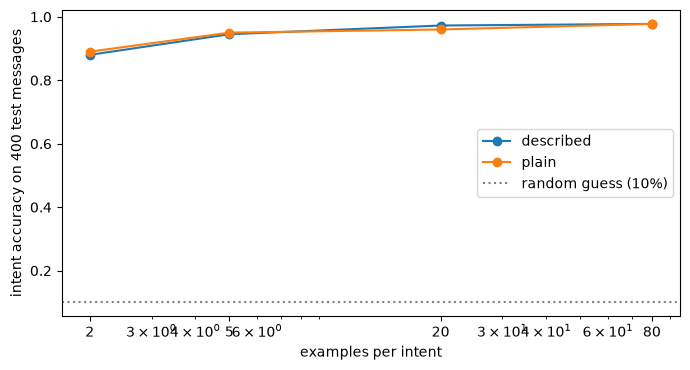

In [10]:
fig, axis = plt.subplots(figsize=(7, 3.8))
for encoding, part in runs.groupby("encoding"):
    axis.plot(part["examples per intent"], part["intent accuracy"], marker="o", label=encoding)
axis.set_xscale("log")
axis.set_xticks([2, 5, 20, 80], labels=["2", "5", "20", "80"])
axis.set_xlabel("examples per intent")
axis.set_ylabel("intent accuracy on 400 test messages")
axis.axhline(0.1, color="grey", linestyle=":", label="random guess (10%)")
axis.legend()
plt.tight_layout()

### Using `confidence` to decide when a person should check

In a process you rarely accept every answer blindly. A common pattern: accept the answer automatically when the model is confident, and send the rest to a person. The table shows, for the 80-examples run, how many messages would be handled automatically at different confidence thresholds, and how accurate those automatic answers are.

In [11]:
answers = answers_by_run[(80, "described")]
predicted = np.array([a["intent"]["choice"] for a in answers])
confidence = np.array([a["intent"]["confidence"] for a in answers])
correct = predicted == test["intent"].to_numpy()
pd.DataFrame([
    {"accept automatically when confidence is at least": threshold,
     "share handled automatically": np.mean(confidence >= threshold),
     "accuracy of automatic answers": correct[confidence >= threshold].mean(),
     "messages sent to a person": int(np.sum(confidence < threshold))}
    for threshold in [0.0, 0.5, 0.8, 0.9]
]).round(3)

,accept automatically when confidence is at least,share handled automatically,accuracy of automatic answers,messages sent to a person
0,0.0,1.000,0.978,0
1,0.5,0.995,0.980,2
2,0.8,0.950,0.997,20
3,0.9,0.928,0.997,29


And the most frequent mistakes, to see whether they make sense (similar needs) or point to unclear options:

In [12]:
mistakes = pd.DataFrame({"actual": test["intent"].to_numpy(), "answered": predicted})[~correct]
mistakes.value_counts().head(8).rename("count").to_frame()

count
actual                   answered                     
card_arrival             lost_or_stolen_card         3
lost_or_stolen_card      card_arrival                1
card_payment_fee_charged cash_withdrawal_charge      1
request_refund           top_up_failed               1
declined_card_payment    top_up_failed               1
top_up_failed            lost_or_stolen_card         1
                         declined_card_payment       1

What this shows in our run:

* A few examples already go a long way: with 2 examples per intent (20 in total) about 88% of the 400 messages got the right intent, with 5 per intent about 95%, with 20 per intent 96-97%, with 80 per intent about 98%. Guessing would give 10%.
* The derived yes/no question (`card`) reached 92-99%.
* `confidence` is useful: accepting only answers with confidence of at least 0.8 handled 95% of the messages automatically at 99.7% accuracy, and sent 20 of 400 to a person.
* Here the two encodings performed about the same, because the intent names already say what they mean. In the small triage example above the descriptions helped. Test both on your own data.
* The remaining mistakes are mostly between related needs (for example "card has not arrived" vs "card lost or stolen"); clearer option descriptions or more examples of those options are the levers.

## Takeaways

* A decision is one RPT call once it is written as a table: past cases as example rows, the input as columns, one column per question.
* Ask for every option (`top_k` = number of options) to get the full probability distribution, and use the probabilities: low `confidence` is the signal to involve a person.
* How the table is written can matter: described options helped in the small triage example and made no difference on the banking messages. Test both on your own labeled data.
* Up to 512 inputs per call; `sap-rpt-1.6` handles up to 2,048 examples, beyond that use `sap-rpt-1.6-large`.
* Measure accuracy on held-out labeled cases before using the answers in a process. On real banking messages, 5 examples per option already gave about 95% accuracy, and a confidence threshold separated reliable from uncertain answers.
* Store the decision definition (questions, criteria, examples, encoding, model) with every stored answer so it stays traceable.